# Image processing notebook, Scinti2024_ZnO

## Settings

### Imports

First, we import all the necessary modules and support functions

In [1]:
import sys
sys.path.append(r'C:\Software\pyerre\framework')
sys.path.append(r'C:\Software\pyerre\proc_functions')
sys.path.append(r'C:\Software\pyninoise')

from magic_selectors import select_basedir, select_directory, \
    select_filesave_fits, select_fileopen_fits, select_roi, \
    select_multiple_rois

from mergers import simple_merge, mrg_medproj, mrg_avgproj_nan, multi_merge

from processors import test_proc, batch_proc, single_proc
from parameters import set_general_scope, set_group_scope, \
    set_params, param

from img_utils import get_img, write_img, crop_img

import numpy as np
import os

%gui qt

### Experiment parameters

Here, we define the experimental parameters

In [2]:
exp_params = {
    'name': 'ZnO',
    'beamline': 'NEUTRA',
    'scintillator': 'LiF-ZnO, unknown thickness, (S/N ?)',
    'pix_size': 87.2, # pixel size in um
    'camera': 'Ikon-L DW936N-BV, S/N unknwon serial number',
    'camera_qe': 0.95, # quantum efficiency of the camera
    'lens': 'Nikkor? 50mm, f/1.4, S/N unknown number',
    'lens_diameter': 35, # lens diameter in mm
    'lens_dist': 350, # distance between lens and scintillator
    'neutron_flux_per_ma': 7.1e6, # flux in n/cm^2/s/mA
    'exposure_time': 1, # exposure time in seconds
    'target_exp': 1350 # target exposure in uAs
}

The following parameters can be computed from the others:

In [3]:
exp_params['p_capt_eff'] = exp_params['lens_diameter']**2/exp_params['lens_dist']**2/16
exp_params['lens_solid_angle'] = exp_params['p_capt_eff']*4*np.pi
exp_params['neutron_flux'] = exp_params['neutron_flux_per_ma']*exp_params['target_exp']/1000
exp_params['n_count'] = exp_params['neutron_flux']*exp_params['exposure_time']*(exp_params['pix_size']*1e-4)**2

### Base Directory

Then, we define the _**base directory**_ for the measurement campaign. All further directories and files will be defined relatively to this base diretory, so that the notebook can be used even if the data is moved somewhere else.

In [4]:
set_params(base_dir = r"C:\Users\zhang_x3\Desktop", general=True)
## %msel select_basedir(default=r"L:\90_projects\93_data\P20210938")

The following parameter can be changed to True to reexecute the notebook skipping the test phases

In [5]:
set_params(skip_testing=False)

### Directory selection

Select the directory corresponding to the analyzed scintillator

In [6]:
set_params(scinti_dir = r"ZnO")
# %msel select_directory('scinti_dir', default=r"04_evaluation\041_images\01_sorted\REFER3")

Select the directory containing the DC images

In [7]:
set_params(dc_dir = r"ZnO\01_dc")
## %msel select_directory('dc_dir', default=r"04_evaluation\041_images\01_sorted\COMMON\99_dc")

### Computation of file and directory names

Compute the names of the sub-directories

In [15]:
set_params(ob_dir = os.path.join(param('scinti_dir'), '03_openbeam'))
set_params(resol_dir = os.path.join(param('scinti_dir'), '02_resol'))
set_params(focus_dir = os.path.join(param('scinti_dir'), '01_focus'))
set_params(sample_dir = os.path.join(param('scinti_dir'), '05_testobject'))

Compute the name of the images directory

In [16]:
set_params(img_dir = os.path.split(os.path.split(param('scinti_dir'))[0])[0])

Compute the names of destination directories and files

In [17]:
set_params(dc_imgf = os.path.join(param('img_dir'), '02_dc_mrg',
            os.path.split(param('scinti_dir'))[1],
            exp_params['name']+'_dc_mrg.fits'))
set_params(ob_imgf = os.path.join(param('img_dir'), '03_ob_mrg',
            os.path.split(param('scinti_dir'))[1],
            exp_params['name']+'_ob_mrg.fits'))
set_params(img_filt_dir = os.path.join(param('img_dir'), '04_filtered',
            os.path.split(param('scinti_dir'))[1]))
set_params(img_avg_dir = os.path.join(param('img_dir'), '05_averaged',
            os.path.split(param('scinti_dir'))[1]))
set_params(sample_filt_imgf = os.path.join(param('img_dir'), '06_sample_smoothed',
            os.path.split(param('scinti_dir'))[1]+'.fits'))
set_params(resol_imgf = os.path.join(param('img_avg_dir'), r'02_resol\02_resol.fits'))
set_params(noise_dir = os.path.join(param('img_filt_dir'), '03_openbeam'))
set_params(sample_imgf = os.path.join(param('img_avg_dir'), r'05_testobject\05_testobject.fits'))
set_params(results_dir = r'04_evaluation\042_results\new_proc_2021-08')

### Selection of the ROIs

Selection of the ROIs for the resolution

In [20]:
%msel select_multiple_rois('resol_rois', param('resol_dir'), default=[[849, 1576, 63, 282], [1113, 1568, 61, 280]])

TypeError: arguments did not match any overloaded call:
  resize(self, a0: QSize): argument 1 has unexpected type 'int'
  resize(self, w: int, h: int): argument 2 has unexpected type 'float'

Selection of the ROI for the focus check

In [19]:
set_params(focus_roi = [833, 860, 366, 356])
# %msel select_roi('focus_roi', param('focus_dir'), default=[833, 860, 366, 356])

Selection of the non changing area (NCA) for the sample intensity correction

In [13]:
set_params(nca = [143, 1496, 172, 137])
## %msel select_roi('nca', param('sample_dir'), default=[143, 1496, 172, 137])

Selection of the histogram ROI

In [14]:
set_params(hist_roi = [162, 1470, 463, 197])
## %msel select_roi('hist_roi', param('sample_dir'), default=[162, 1470, 463, 197])

Selection of the ROI for the contrast measurement

In [15]:
set_params(contrast_roi = [437, 1505, 259, 144])
## %msel select_roi('contrast_roi', param('sample_dir'), default=[437, 1505, 259, 144])

## Processing sequence definition

### DC correction

In this step, the DC image is simply subtracted pixel-wise from the source image

In [16]:
def dc_corr(src_img, header, dc_img, **kwargs):
    
    header['HISTORY'] = 'Processing: DC correction applied'
    
    return src_img.astype(float) - dc_img

### White spots filter (3D)

The white spots are removed by applying a 3D outlier filter of size 'ws_filter_size'. This parameter can either be a single value (in which case the filter size is the same in all dimension) or a 3-elements list with the sizes in x, y and z directions (z being the image number). The other filter parameter is the threshold.

For this processing, we use the "ro_filter_3D" defined in the "filters" module of the framework.

In [17]:
def ws_filter(src_img, header, ws_filter_size, ws_threshold, type_replace='nan', **kwargs):
    
    from filters import ro_filter_3D
    
    dst_img = ro_filter_3D(src_img, filter_size=ws_filter_size,
                           threshold=ws_threshold, **kwargs, type_replace=type_replace)
    
    header['HISTORY'] = 'Processing: WS filter applied'
    
    return dst_img

### Intensity correction

In [18]:
def int_corr(src_img, header, target_exp, **kwargs):
    
    img_int = float(eval(header['detector/exp_avg']))
    
    dst_img = src_img * target_exp / img_int
    
    header['HISTORY'] = 'Processing: OB correction applied'
    
    return dst_img

### Open beam correction

in this step, the working image is divided by the defined open beam image

In [19]:
def ob_corr(src_img, header, ob_img, **kwargs):
    
    dst_img = src_img / ob_img
    
    header['HISTORY'] = 'Processing: OB correction applied'
    
    return dst_img

### Sequence definition

The sequence is finally specified as being the succesion of the previously defined steps.

In [20]:
seq_main = [
    'raw',
    dc_corr,
    ws_filter,
    int_corr,
    'filtered',
    ob_corr,
    'processed'
]

## Adjusting the processing parameters

Here, we will adjust the parameters of the processing

In [21]:
set_params(target_exp = exp_params['target_exp'])

### Creation of the merged DC image

We perform the merge using the __*simple_merge()*__ function. The merging process is defined as being a median projection.

In [22]:
simple_merge(
    src = param('dc_dir'),
    dst = param('dc_imgf'),
    merger = mrg_medproj
)

31.08.2021 - 16:42:40 - Processing start (user: 'boillat')
Destination file "04_evaluation\041_images\02_dc_mrg\REFER3\REFER3_dc_mrg.fits" already exists, skipping"
31.08.2021 - 16:42:40 - Processing complete
Elapsed time: 0:00:00


### Adjusting the white spots filter parameters

#### Adjusting the threshold

We select a region of interest (ROI) of 1024x1024 pixels in the center for noise analysis (this will also be used later on)

In [23]:
set_params(noise_roi = [512, 512, 1024, 1024])

The *ro_auto_threshold()* function is used to automatically extract the outliers threshold. The standard deviation is evaluated based on the median absolute deviation (MAD) - a methos which is robust against the presence of outliers. Then, the threshold is chosen base on a 99% confidence interval.

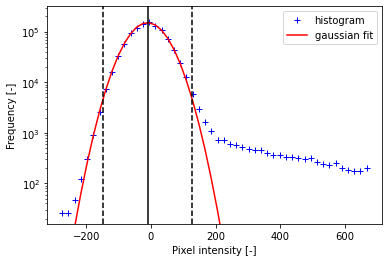

Estimated noise standard deviation:  53.373599999999996
Selected threshold:  137.48128291589757


In [24]:
from filters import ro_auto_threshold
set_params(ws_threshold = ro_auto_threshold(
    param('ob_dir'),
    param('noise_roi'),
    test_filter_size = 9
))

####  Adjusting the filter size

And a region of interest:

In [25]:
print(param('sample_filt_imgf'))

04_evaluation\041_images\06_sample_smoothed\REFER3.fits


In [26]:
set_params(test_roi = [1034, 791, 378, 392])
## %msel select_roi('test_roi', param('sample_dir'), default=[1034, 791, 378, 392])

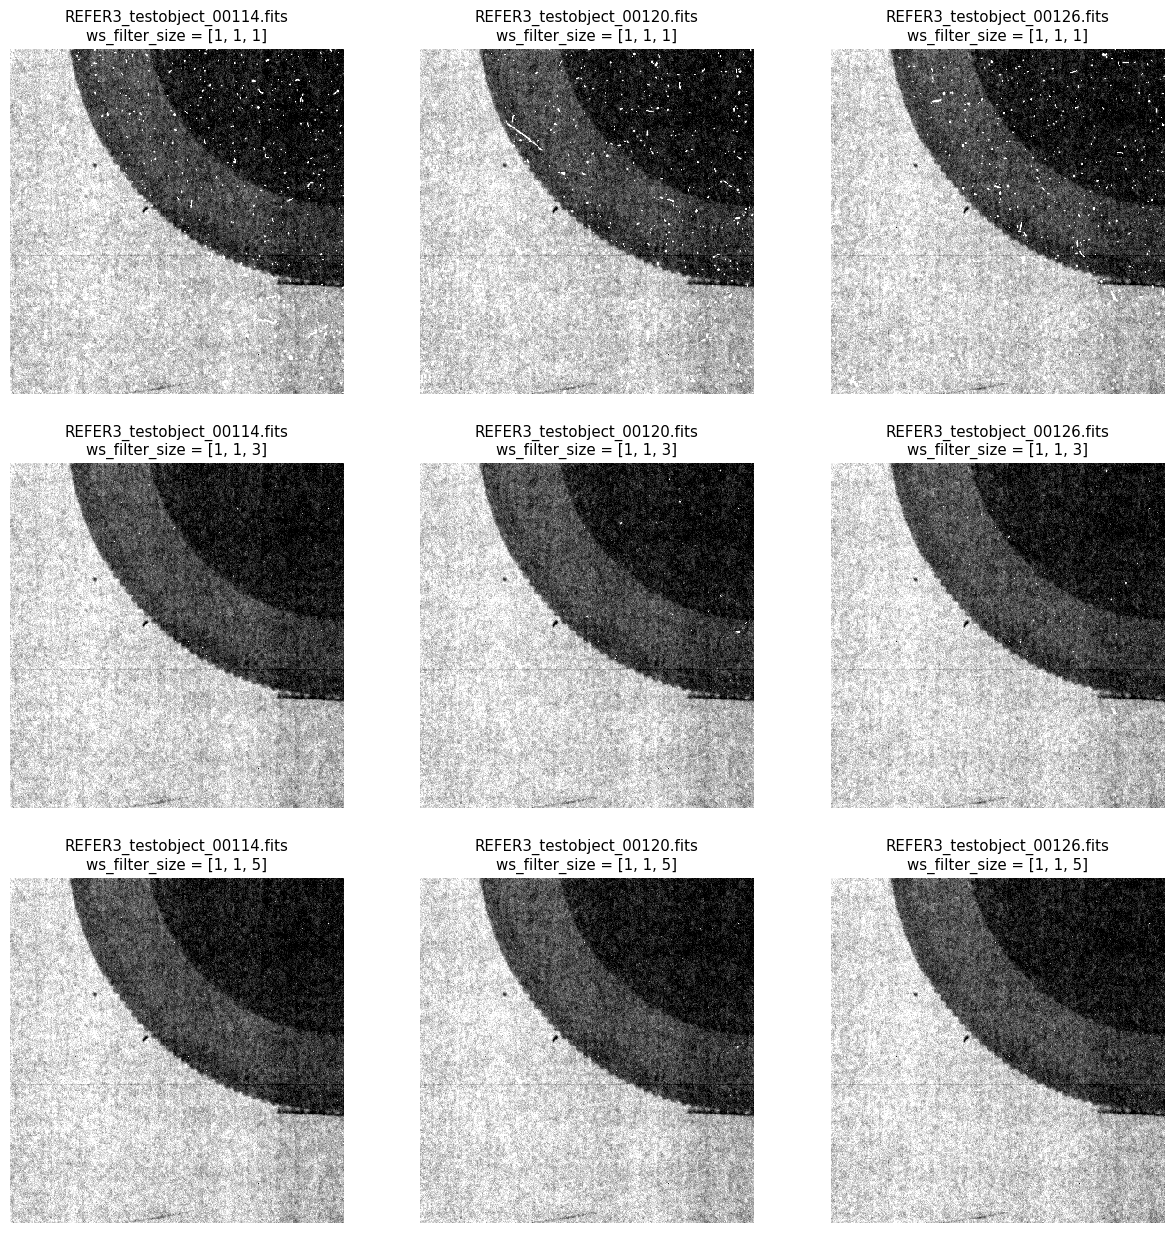

In [27]:
test_proc(
    src = param('sample_dir'),
    seq = seq_main,
    proc_to = 'filtered',
    roi = param('test_roi'),
    type_replace = 'med',
    test_param = 'ws_filter_size',
    test_values = ([1,1,1],[1,1,3],[1,1,5]),
    nimg = 3,
    ncols = 3
)

Based on these results, we choose a filter size:

In [28]:
set_params(ws_filter_size = [1,1,5])

### Setup the open beam correction

We perform the merge of the open beam. This time, we include a pre-processing sequence.

In [29]:
simple_merge(
    src = param('ob_dir'),
    dst = param('ob_imgf'),
    merger = mrg_avgproj_nan,
    seq = seq_main,
    proc_to = 'filtered'
)

31.08.2021 - 16:43:13 - Processing start (user: 'boillat')
Destination file "04_evaluation\041_images\03_ob_mrg\REFER3\REFER3_ob_mrg.fits" already exists, skipping"
31.08.2021 - 16:43:13 - Processing complete
Elapsed time: 0:00:00


## Apply filtering to all images

When everything is set up, the batch processing can be applied to all images. 

In [30]:
batch_proc(
    src = param('scinti_dir'),
    dst = param('img_filt_dir'),
    seq = seq_main
)

31.08.2021 - 16:43:13 - Processing start (user: 'boillat')
137 files out of 171 were skipped because the destination does already exist



31.08.2021 - 16:43:53 - Processing complete
Elapsed time: 0:00:40
Iteration count: 34
Time per iteration: 1.18s


## Merge images

Here, we will merge together all images from a given folder.

The *multi_merge* function groups all images from a given folder and computed and average image. The *mrg_avgproj_nan* merger is used: for each pixel, the average of all valid values from the individual images is computed. The NaN values (resulting of the white spot filtering) are ignored.

In [31]:
multi_merge(
    src_dir = param('img_filt_dir'),
    dst_dir = param('img_avg_dir'),
    merger = mrg_avgproj_nan,
)

31.08.2021 - 16:43:53 - Processing start (user: 'boillat')


Destination file "04_evaluation\041_images\05_averaged\REFER3\01_focus\01_focus.fits" already exists, skipping"
Destination file "04_evaluation\041_images\05_averaged\REFER3\02_resol\02_resol.fits" already exists, skipping"
Destination file "04_evaluation\041_images\05_averaged\REFER3\03_openbeam\03_openbeam.fits" already exists, skipping"
Destination file "04_evaluation\041_images\05_averaged\REFER3\04_afterglow\04_afterglow.fits" already exists, skipping"
Destination file "04_evaluation\041_images\05_averaged\REFER3\05_testobject\05_testobject.fits" already exists, skipping"
Destination file "04_evaluation\041_images\05_averaged\REFER3\06_gamma\06_gamma.fits" already exists, skipping"


C:\Software\pyerre\framework\mergers.py:67: RuntimeWarning: Mean of empty slice
  return np.nanmean(src_stack, axis=2).astype(src_stack.dtype)



31.08.2021 - 16:44:03 - Processing complete
Elapsed time: 0:00:09
Iteration count: 143
Time per iteration: 0.07s


## Focus check

We check the focus position:

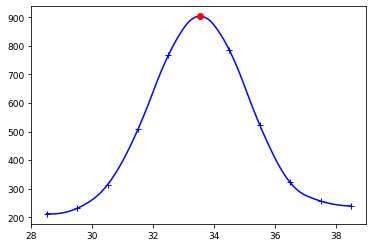

Best focus position: 33.5 mm
Used focus position: 33.5 mm
Focus error: -0.0 mm


In [32]:
from P20210938_focus_check import focus_check
exp_params['focus_error'] = focus_check(param('focus_dir'), param('resol_dir'), param('focus_roi'))

## Resolution measurement

First we load the resolution pattern image

In [33]:
from img_utils import get_img, show_img
resol_img = np.nan_to_num(get_img(param('resol_imgf'), param('base_dir')))

The *meas_resol()* function measures the resolution by first identifying the main edge in each ROI, extracting an edge spread function (ESF), and computing the line spread function (LSF) as its derivate. The LSF is fitted using a Voigt function (convolution of a Gaussian and a Lorentzian). The two corresponding parameters (sigma and gamma) for each ROI are returned.

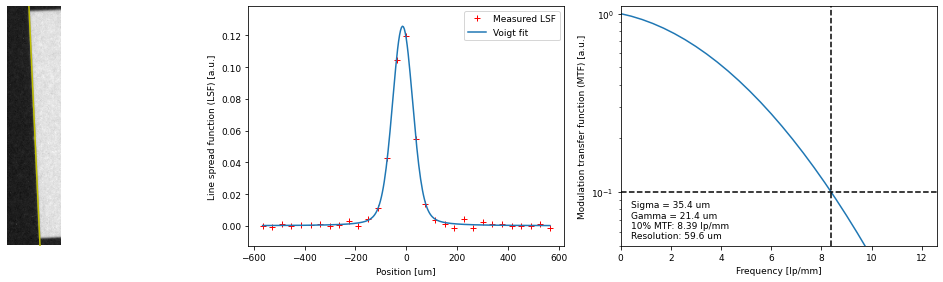

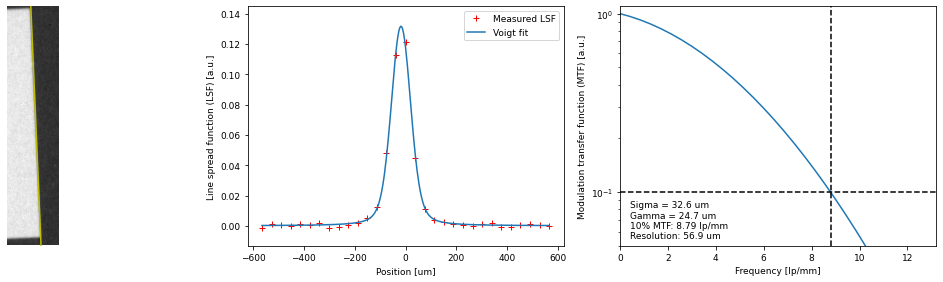

In [34]:
from resolution import meas_resol
sigma_vals, gamma_vals, mtf_vals = meas_resol(resol_img, param('resol_rois'), pix_size=exp_params['pix_size'])

We add the *sigma* and *gamma* average values to the list of experimental parameters

In [35]:
sigma = np.average(sigma_vals)
gamma = np.average(gamma_vals)
exp_params['sigma'] = sigma
exp_params['gamma'] = gamma
exp_params['resol'] = 1000*((gamma**2 + 8*np.log(10)*sigma**2)**0.5 - gamma)/(4*np.pi*sigma**2)

## Noise analysis

The first parameter we measure is the fraction of pixels identified as white spots and replaced

In [36]:
from file_utils import file_list
from tqdm.notebook import tqdm
flist = file_list(param('noise_dir'), param('base_dir'))
ws_count = 0
for fname in tqdm(flist):
    img = get_img(os.path.join(param('noise_dir'), fname), param('base_dir'))
    ws_count = ws_count + len(np.where(np.isnan(img))[0])
exp_params['ws_fraction'] = ws_count/(len(flist)*img.size)
print('White spots fraction: ', exp_params['ws_fraction'])


White spots fraction:  0.02135924356324332


Here, we will analyze the noise power spectrum (NPS) and combine it with the modulation transfer function (MTF) defined by the resolution parameters measured in the previous section. The detective quantum efficiency (DQE) is calculated from these two functions using the following formula:

\begin{equation*}
DQE(k) = \frac{MTF(k)^2}{n \cdot NPS(k)}
\end{equation*}

Where *n* is the neutron count per pixel and *k* is the spatial frequency.

The average photon count (over the defined ROI) is extracted from the average open ebam image (for the Ikon-L camera with the chosen acquisition parameters, the counts in the images are equal to the number of detected photons, so no scaling factor is necessary):

In [37]:
from img_utils import get_img, crop_img
exp_params['p_count'] = np.nanmean(crop_img(get_img(param('ob_imgf'), param('base_dir')), param('noise_roi')))
exp_params['light_output'] = exp_params['p_count']/exp_params['n_count']/exp_params['lens_solid_angle']/exp_params['camera_qe']

Here, we compute the noise power spectrum using two different methods. The "FFT" method directly uses a Fourier transform of the noise image. Because of the missing data due to the white spots, 3 images are averaged together, and the measured power spectrum on this average is multiplied by 3. The power spectrum is obtained from the square of the Fourier transform, each point of the spectrum corrsponding to the average of a ring in the frequency domain. The "AC" method first computes the auto-correlation function, and then extracts its Fourier transform - which is equal to the square of the Fourier transform of the original image. This method allows the use of a single image with missing data.

In [38]:
from pyninoise import get_powspec
k, nps_fft = get_powspec(param('noise_dir'), roi=param('noise_roi'), pix_size=exp_params['pix_size'], method='fft')
k, nps_ac = get_powspec(param('noise_dir'), roi=param('noise_roi'), pix_size=exp_params['pix_size'], method='ac')

The MTF is computed from the *sigma* and *gamma* resolution parameters:

In [39]:
mtf = np.exp(-2*np.pi**2*(exp_params['sigma']/1000)**2*k**2-np.pi*(exp_params['gamma']/1000)*k)

And the DQE for the power spectrums obtained using both methods described above (FFT and AC) is computed:

In [40]:
dqe_fft = mtf**2/nps_fft/exp_params['n_count']
dqe_ac = mtf**2/nps_ac/exp_params['n_count']

We extract the NPS value for the lowest and highest frequency:

In [41]:
exp_params['nps_lf'] = nps_ac[0]
exp_params['nps_hf'] = nps_ac[-1]

We extract the DQE values of interest

In [42]:
exp_params['dqe_lf'] = dqe_ac[0]
exp_params['dqe_max'] = 1/((1/(dqe_ac[0]*exp_params['n_count'])-nps_ac[-1])*exp_params['n_count'])

After this, we plot the resulting NPS and DQE:

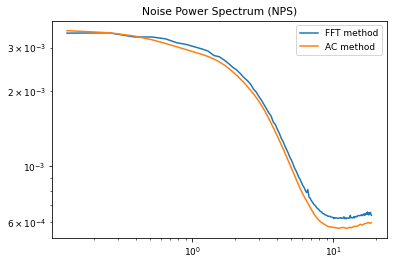

In [43]:
import matplotlib.pyplot as plt
plt.loglog(k, nps_fft)
plt.plot(k, nps_ac)
plt.title('Noise Power Spectrum (NPS)')
plt.legend(['FFT method', 'AC method'])
plt.show()

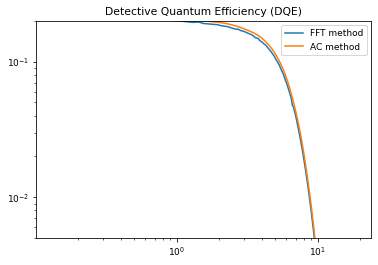

In [44]:
plt.loglog(k, dqe_fft)
plt.plot(k, dqe_ac)
plt.ylim(bottom=0.005, top=0.2)
plt.title('Detective Quantum Efficiency (DQE)')
plt.legend(['FFT method', 'AC method'])
plt.show()

## Res-Noise curves

In [45]:
from pyninoise import get_resnoise

Get the sample image directory and the ROI to measure the noise

In [46]:
df_rn_curve = get_resnoise(
    param('noise_dir'),
    resol_img,
    resol_rois = param('resol_rois'),
    noise_roi = param('noise_roi'),
    pix_size = exp_params['pix_size'],
    img_count = 1
)


Replaced pixels fraction: 2.072596549987793%


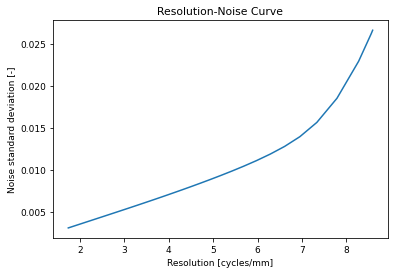

In [47]:
import matplotlib.pyplot as plt
plt.title('Resolution-Noise Curve')
plt.plot(df_rn_curve['resol'], df_rn_curve['std'])
plt.xlabel('Resolution [cycles/mm]')
plt.ylabel('Noise standard deviation [-]')
plt.show()

## Generation of image at defined resolution

We define the target resolution in cycles/mm

In [48]:
target_resol = 3

### Setup of the filter

We interpolate the filter sigma - resolution curve to get the sigma value needed to obtain the target resolution:

In [49]:
from scipy.interpolate import interp1d
rn_interp = interp1d(np.array(df_rn_curve['resol'])[1:],
                     np.array(df_rn_curve.index)[1:],
                     kind='linear')

In [50]:
sigma_filter = float(rn_interp(target_resol))
print('Sigma for filter: ', sigma_filter)
exp_params['sigma_filter'] = sigma_filter

Sigma for filter:  2.744376077401122


We apply the filter to the resolution test image

In [51]:
from scipy.ndimage import gaussian_filter
resol_img_filt = gaussian_filter(resol_img, sigma_filter)

We verify the obtained resolution:

In [52]:
_, _, mtf_vals_filt = meas_resol(resol_img_filt, param('resol_rois'), pix_size=exp_params['pix_size'], silent=True)
print('MTF resolution after filtering: ', np.mean(mtf_vals_filt), ' cycles/mm')

MTF resolution after filtering:  2.999727676561913  cycles/mm


### Generation of the filtered image

We open the source image:

In [53]:
sample_img = get_img(param('sample_imgf'), param('base_dir'))

We apply the filter and correct the intensity:

In [54]:
sample_img_filt = gaussian_filter(sample_img, sigma_filter)
sample_img_filt = sample_img_filt / np.nanmean(crop_img(sample_img_filt, param('nca')))

And we save the filtered image:

In [55]:
write_img(sample_img_filt, param('sample_filt_imgf'), param('base_dir'))

Could not write the destination image: File 'L:\\90_projects\\93_data\\P20210938\\04_evaluation\\041_images\\06_sample_smoothed\\REFER3.fits' already exists.


### Noise / SNR at defined resolution

Create the interpolation function to get the noise at a defined filtering level

In [56]:
from scipy.interpolate import interp1d
fn_interp = interp1d(np.array(df_rn_curve.index)[1:],
                     np.array(df_rn_curve['std'])[1:],
                     kind='linear')

Get the noise image

In [57]:
from file_utils import file_list
noise_img = get_img(os.path.join(param('noise_dir'), file_list(param('noise_dir'), param('base_dir'))[0]), param('base_dir'))

Compute the corresponsing noise (standard deviation) and the SNR

In [58]:
exp_params['noise_filt'] = fn_interp(sigma_filter)
exp_params['SNR_filt'] = 1/exp_params['noise_filt']
print('Noise: {:4f} / SNR: {:4f}'.format(exp_params['noise_filt'], exp_params['SNR_filt']))

Noise: 0.005274 / SNR: 189.605970


### Histogram generation and contrast measurement

We display the image with the regions of interest

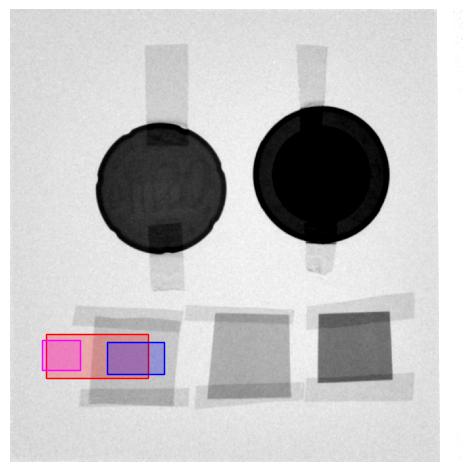

In [59]:
show_img(sample_img_filt, dr=[(param('hist_roi'), 'red'), 
                              (param('contrast_roi'), 'blue'),
                              (param('nca'), 'magenta')], wmax=300)

We define the range for the histogram

In [60]:
hist_range = (0.9, 1.1)
hist_bins = 500

We compute the histogram:

In [61]:
h_freq, h_int = np.histogram(crop_img(sample_img_filt, param('hist_roi')), hist_bins, hist_range)
h_int = (h_int[:-1]+h_int[1:])/2

And display it:

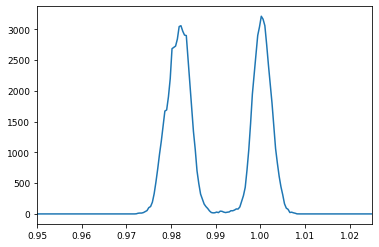

In [62]:
plt.plot(h_int, h_freq)
plt.xlim(left = 0.95, right = 1.025)
plt.show()

Compute and display the contrast:

In [63]:
exp_params['contrast'] = 1 - np.nanmean(crop_img(sample_img_filt, param('contrast_roi')))

In [64]:
print('Contrast: ', exp_params['contrast'])

Contrast:  0.017174488640594232


Compute and display the signal-to-noise ratio (SNR) curve as a function of resolution

In [65]:
df_rn_curve['SNR'] = 1.0/df_rn_curve['std']

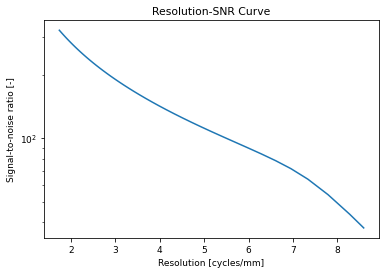

In [66]:
import matplotlib.pyplot as plt
plt.title('Resolution-SNR Curve')
plt.semilogy(df_rn_curve['resol'], df_rn_curve['SNR'])
plt.xlabel('Resolution [cycles/mm]')
plt.ylabel('Signal-to-noise ratio [-]')
plt.show()

## Output results

The name of the file is computed based on the experiment name:

In [67]:
import os
dst_file = os.path.join(param('base_dir'), param('results_dir'), exp_params['name']+'.xlsx')
summary_file = os.path.join(param('base_dir'), param('results_dir'), 'summary.xlsx')

We create panda frames of the parameters and results:

In [68]:
import pandas as pd
df_spectra = pd.DataFrame({
    'k':k,
    'mtf':mtf,
    'nps_fft':nps_fft,
    'nps_ac':nps_ac,
    'dqe_fft':dqe_fft,
    'dqe_ac':dqe_ac
})
df_params = pd.DataFrame({'Values':[exp_params[x] for x in exp_params.keys()]},
                         index=exp_params.keys())
df_histogram = pd.DataFrame({'int': h_int, 'freq':h_freq})
df_summary = pd.DataFrame(exp_params, index=[exp_params['name']])

And write to the destination file:

In [69]:
with pd.ExcelWriter(dst_file) as writer:
    df_params.to_excel(writer, sheet_name='Parameters')
    df_spectra.to_excel(writer, sheet_name='Spectra')
    df_rn_curve.to_excel(writer, sheet_name='R-N Curve')
    df_histogram.to_excel(writer, sheet_name='Histogram')

In [70]:
if os.path.exists(summary_file):
    df = pd.read_excel(summary_file, sheet_name='Summary', engine='openpyxl', index_col=0)
    df.loc[exp_params['name']] = df_summary.loc[exp_params['name']]
    df.to_excel(summary_file, sheet_name='Summary')
else:
    df_summary.to_excel(summary_file, sheet_name='Summary')